In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
cwd = Path.cwd()
project_root = cwd.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
    print('Done!')

Done!


In [3]:
data_path = project_root / 'data' / 'processed' / 'demand_development.csv'
demand_data = pd.read_csv(data_path)

In [4]:
demand_data.head()

,timestamp_utc,interval_end_utc,timestamp_london,settlement_date,settlement_period,demand_mw,neso_day_ahead_forecast_mw,historic_nd_mw,historic_tsd_mw,forecast_issue_utc,...,match_id,opponent,scheduled_kickoff_utc,match_stage,event_role,temperature_london_c_retrospective,temperature_manchester_c_retrospective,temperature_birmingham_c_retrospective,temperature_proxy_c_retrospective,weather_ex_ante_eligible
0,2023-01-01 00:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01 00:00:00+00:00,2023-01-01,1,20967,20320,21043,24680,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaN,NaN,NaN,11.60,9.00,9.1,9.900000,False
1,2023-01-01 00:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01 00:30:00+00:00,2023-01-01,2,21699,20680,21756,25289,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaN,NaN,NaN,11.55,8.85,9.0,9.800000,False
2,2023-01-01 01:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01 01:00:00+00:00,2023-01-01,3,21185,20498,21348,25269,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaN,NaN,NaN,11.50,8.70,8.9,9.700000,False
3,2023-01-01 01:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01 01:30:00+00:00,2023-01-01,4,20442,19955,20586,24574,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaN,NaN,NaN,11.35,8.50,8.7,9.516667,False
4,2023-01-01 02:00:00+00:00,2023-01-01 02:30:00+00:00,2023-01-01 02:00:00+00:00,2023-01-01,5,19633,19512,19781,24135,2022-12-31 08:45:00+00:00,...,NaN,NaN,NaN,NaN,NaN,11.20,8.30,8.5,9.333333,False


In [6]:
utc_columns = [
    'timestamp_utc',
    'interval_end_utc',
    'forecast_issue_utc',
    'forecast_cutoff_utc',
    'scheduled_kickoff_utc',
]

for column in utc_columns:
    demand_data[column] = pd.to_datetime(
        demand_data[column], utc=True
    )

In [7]:
demand_data['settlement_date'] = pd.to_datetime(
    demand_data['settlement_date']
)

In [5]:
demand_data.columns

Index(['timestamp_utc', 'interval_end_utc', 'timestamp_london',
       'settlement_date', 'settlement_period', 'demand_mw',
       'neso_day_ahead_forecast_mw', 'historic_nd_mw', 'historic_tsd_mw',
       'forecast_issue_utc', 'forecast_cutoff_utc', 'neso_available_at_cutoff',
       'Datetime', 'Publish_Datetime', 'TRIAD_Avoidance_Estimate',
       'hour_of_week', 'half_hour_of_week', 'is_bank_holiday_england_wales',
       'is_bank_holiday_scotland', 'is_bank_holiday_any_gb', 'data_split',
       'baseline_fit_eligible', 'is_england_match_day', 'match_id', 'opponent',
       'scheduled_kickoff_utc', 'match_stage', 'event_role',
       'temperature_london_c_retrospective',
       'temperature_manchester_c_retrospective',
       'temperature_birmingham_c_retrospective',
       'temperature_proxy_c_retrospective', 'weather_ex_ante_eligible'],
      dtype='str')

In [8]:
train = demand_data.loc[
    demand_data['data_split'].eq('train')
].copy()

/var/folders/69/dxynlnqj6413x3bgy4c63zhc0000gn/T/ipykernel_54052/1906577666.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


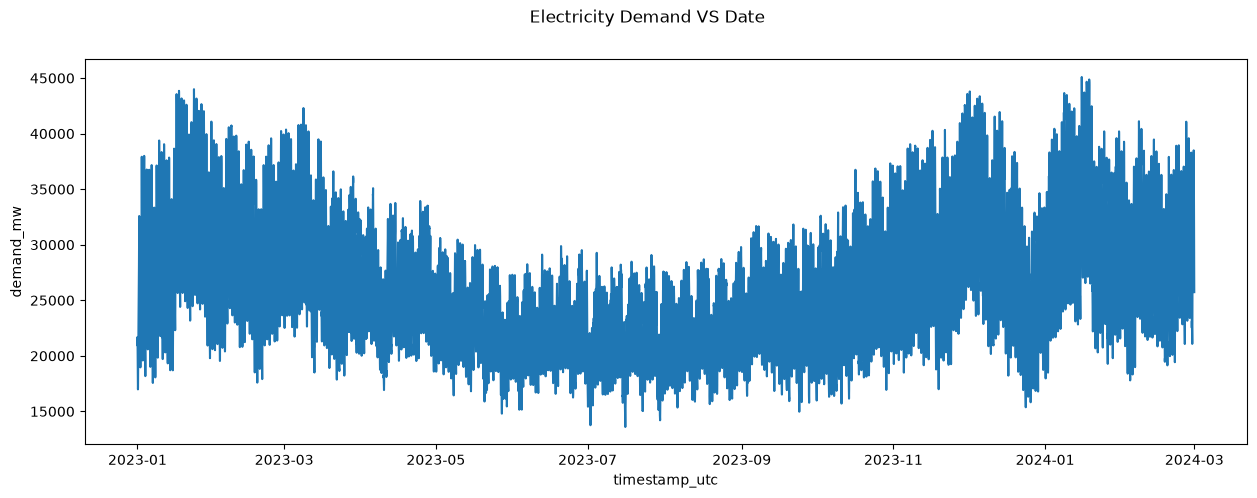

In [12]:
fig, ax = plt.subplots(figsize=(15, 5))

sns.lineplot(
    data=train,
    x='timestamp_utc',
    y='demand_mw',
    ax=ax
)

fig.suptitle('Electricity Demand VS Date')
fig.show()

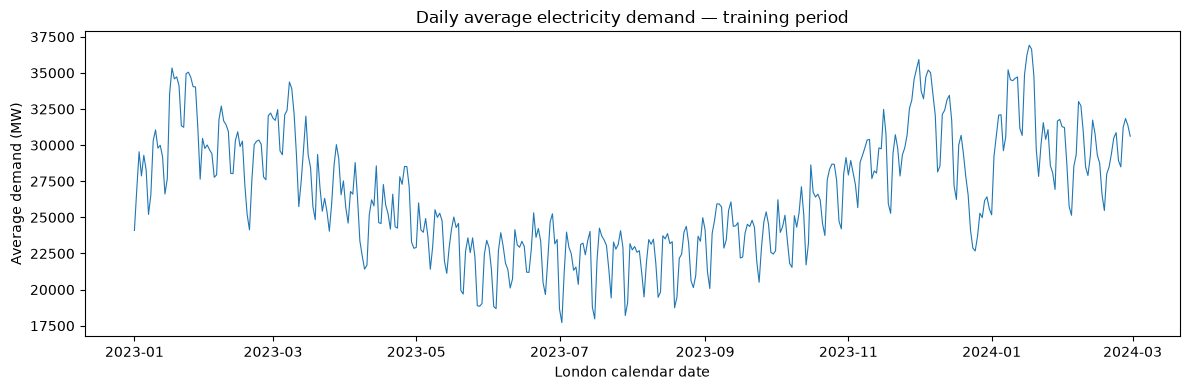

In [14]:
daily_mean = (
    train.groupby(by='settlement_date')['demand_mw']
    .mean()
)

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(daily_mean.index, daily_mean.values, linewidth=0.8)
ax.set(
    title='Daily average electricity demand — training period',
    xlabel='London calendar date',
    ylabel='Average demand (MW)'
)

fig.tight_layout()
plt.show()